<CodeBlock language="markdown"># Gym Data Cleaning and Exploratory Data Analysis
Author: NEO
Academic Context: Talendig AI/ML Training — Month 4, Week 2
Project Type: Data Cleaning and Exploratory Data Analysis (EDA)
Language: Python
Project Overview
This project focuses on inspecting, cleaning, and validating a gym customer dataset containing missing values, duplicate records, and incorrectly represented data types.
The dataset represents customers from three gym branches in Santo Domingo, Dominican Republic: Naco, Piantini, and Gazcue.
Objectives
- Understand the structure and quality of the dataset.
- Identify missing values and assess their possible causes.
- Handle missing values using justified strategies.
- Detect and remove duplicate records.
- Correct data types when necessary.
- Compare the mean and median of customer ages.
- Validate the cleaned dataset and export the results.
Important Context: Missing Emails
The gym began requesting email addresses only a few months ago. Therefore, many older customer records do not contain an email address.
These missing values may reflect the historical data collection process rather than data entry errors. This context will guide the analysis and cleaning decisions.
Project Scope
This project focuses on data quality, preprocessing, and exploratory analysis. It does not claim to train a predictive machine learning model.</CodeBlock>

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Configuración visual de los gráficos
sns.set_theme(style="whitegrid")

# Mostrar los números con dos decimales cuando corresponda
pd.set_option("display.float_format", "{:.2f}".format)

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Pandas version: 3.0.6
NumPy version: 2.5.4


<CodeBlock language="markdown">## 1. Data Loading
The first step is to load the original dataset and verify that the file is accessible.
The CSV file is stored in the data/ directory, while this notebook is stored in notebooks/.
We will locate the file using pathlib so that the notebook can work whether the current working directory is the project root or the notebooks/ directory.
The original dataset will remain unchanged. All cleaning operations will be performed in memory, and the cleaned dataset will be exported separately.</CodeBlock>

In [4]:
# Cargar los datos (Code)

# Posibles ubicaciones según el directorio de trabajo de Jupyter
possible_paths = [
    Path("data/clientes_gimnasio.csv"),
    Path("../data/clientes_gimnasio.csv"),
]

DATA_PATH = next(
    (path.resolve() for path in possible_paths if path.exists()),
    None
)

if DATA_PATH is None:
    raise FileNotFoundError(
        "No se encontró clientes_gimnasio.csv. "
        "Comprueba que el archivo esté dentro de la carpeta data/."
    )

DATA_DIR = DATA_PATH.parent

# Cargar el dataset original
df_original = pd.read_csv(DATA_PATH)

# Crear una copia para trabajar sin alterar el DataFrame original
df = df_original.copy()

print("Dataset loaded successfully.")
print(f"File: {DATA_PATH.name}")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")

Dataset loaded successfully.
File: clientes_gimnasio.csv
Rows: 63
Columns: 7


<CodeBlock language="markdown">## 2. Initial Data Inspection
Before modifying the dataset, we need to understand its structure.
We will inspect:
- The number of rows and columns.
- The first records.
- Column names and data types.
- The general structure of the dataset.
This step helps identify potential issues before applying any cleaning operations.</CodeBlock>

In [5]:
# Explorar los datos (Code)

print("Dataset dimensions:", df.shape)

display(df.head())

print("\nColumn data types:")
display(df.dtypes.to_frame(name="Data Type"))

print("\nDataset information:")
df.info()

Dataset dimensions: (63, 7)


,ClienteID,Nombre,Edad,Plan,Sucursal,DiasAsistidosMes,Email
0,56,Carlos Fernandez,64.00,1,Naco,4,carlos56@gmail.com
1,17,Juan Reyes,47.00,3,Naco,29,NaN
2,8,Yolanda Castillo,52.00,3,Naco,30,NaN
3,25,Francisco Garcia,43.00,1,Naco,25,NaN
4,7,Patricia Rodriguez,NaN,2,Naco,23,NaN



Column data types:


,Data Type
ClienteID,int64
Nombre,str
Edad,float64
Plan,int64
Sucursal,str
DiasAsistidosMes,int64
Email,str



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 63 entries, 0 to 62
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ClienteID         63 non-null     int64  
 1   Nombre            63 non-null     str    
 2   Edad              52 non-null     float64
 3   Plan              63 non-null     int64  
 4   Sucursal          61 non-null     str    
 5   DiasAsistidosMes  63 non-null     int64  
 6   Email             16 non-null     str    
dtypes: float64(1), int64(3), str(3)
memory usage: 3.6 KB


<CodeBlock language="markdown">## 3. Missing Value Assessment
Missing values can reduce the quality and usefulness of a dataset. However, their presence does not automatically mean that the data is incorrect.
We will calculate both the number and percentage of missing values in each column.
The percentage is calculated as:
Missing percentage = (Missing values / Total rows) × 100
This allows us to compare missingness across columns, even when the number of missing values differs.</CodeBlock>

In [6]:
# Cuantificar los nulos (Code)

missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2),
})

missing_summary = missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing_summary)

,Missing Count,Missing Percentage
Email,47,74.60
Edad,11,17.46
Sucursal,2,3.17
Nombre,0,0.00
ClienteID,0,0.00
Plan,0,0.00
DiasAsistidosMes,0,0.00


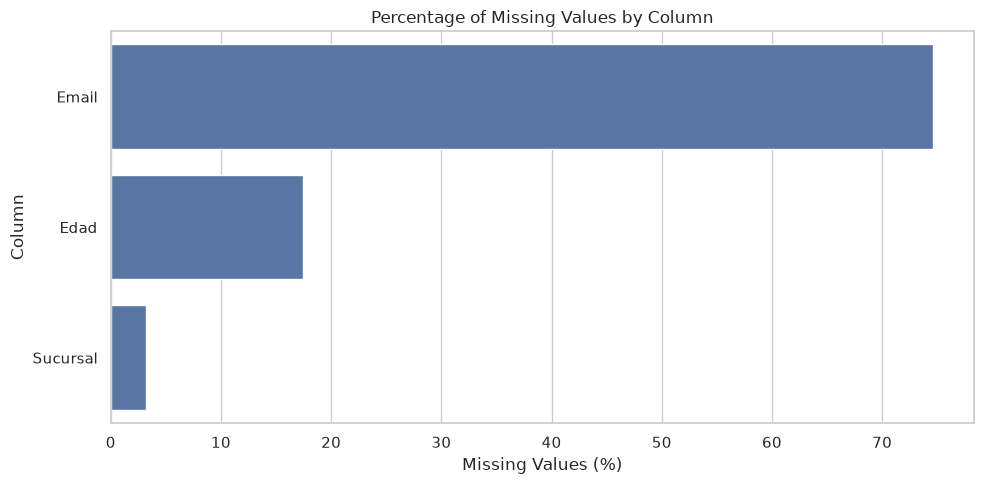

In [7]:
# Visualizar los nulos (Code)

missing_percentages = (
    df.isnull().mean().mul(100).sort_values(ascending=False)
)

missing_percentages = missing_percentages[
    missing_percentages > 0
]

if not missing_percentages.empty:
    plt.figure(figsize=(10, 5))

    sns.barplot(
        x=missing_percentages.values,
        y=missing_percentages.index
    )

    plt.title("Percentage of Missing Values by Column")
    plt.xlabel("Missing Values (%)")
    plt.ylabel("Column")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values were found.")

<CodeBlock language="markdown">## 4. Understanding Missing Email Values
The dataset documentation explains that the gym introduced email collection only a few months ago.
Therefore, missing email values may be related to when each customer registered. They should not automatically be treated as data entry errors.
We will not invent email addresses or use statistical imputation for this column.
For this project's analytical dataset, we will exclude the Email column, following the original cleaning approach. This is a project-specific decision: if email addresses were needed for customer communication or another analysis, we would preserve the column and handle its missingness differently.</CodeBlock>

<CodeBlock language="markdown">## 5. Duplicate Record Detection
Duplicate records can distort statistical summaries and downstream analyses.
We will identify exact duplicate rows in the original dataset and remove them before imputing missing values or excluding columns.
This approach avoids accidentally treating records as duplicates merely because a column was removed during preprocessing.
Note that exact duplicate detection does not identify every possible duplicate customer. Identifying the same person across different records may require a unique customer identifier and additional business rules.</CodeBlock>

In [ ]:
# Detectar y eliminar duplicados (Code)

# Contar los registros duplicados completos
duplicate_count = df.duplicated().sum()

print("Duplicate rows found:", duplicate_count)

# Eliminar duplicados exactos
df = df.drop_duplicates().copy()

print("Rows after duplicate removal:", len(df))
print("Rows removed:", duplicate_count)

Duplicate rows found: 3
Rows after duplicate removal: 60
Rows removed: 3


<CodeBlock language="markdown">## 6. Missing Value Treatment
Different columns require different strategies depending on their meaning.
Age
Age is a numerical variable. We will replace missing values with the median age.
The median is the middle value when observations are ordered. It is generally less sensitive to extreme values than the mean.
Sucursal
Sucursal is a categorical variable representing the gym branch. We will use the mode, which is the most frequent category, to fill missing values.
This assumes that assigning the most common branch is acceptable for the purpose of this exercise. It does not recover the customer's actual branch with certainty.
Email
We will exclude Email from the analytical dataset because many values are missing and the column is not required for the current analysis.
This does not mean that every column with many missing values should automatically be deleted.</CodeBlock>

In [9]:
# Aplicar la limpieza (Code)

# Guardar la mediana y la moda para documentar las decisiones
age_median = df["Edad"].median()
branch_mode = df["Sucursal"].mode()

if pd.isna(age_median):
    raise ValueError(
        "No se puede imputar Edad: no hay valores válidos."
    )

if branch_mode.empty:
    raise ValueError(
        "No se puede imputar Sucursal: no hay una moda disponible."
    )

branch_mode = branch_mode.iloc[0]

# Imputar los valores faltantes de Edad
df["Edad"] = df["Edad"].fillna(age_median)

# Imputar los valores faltantes de Sucursal
df["Sucursal"] = df["Sucursal"].fillna(branch_mode)

# Excluir Email del dataset analítico
if "Email" in df.columns:
    df = df.drop(columns=["Email"])

print(f"Median used for Edad: {age_median}")
print(f"Mode used for Sucursal: {branch_mode}")

print("\nMissing values after treatment:")
display(df.isnull().sum().to_frame(name="Remaining Nulls"))

print("\nTotal remaining missing values:", df.isnull().sum().sum())
print("Shape after missing value treatment:", df.shape)

Median used for Edad: 47.0
Mode used for Sucursal: Naco

Missing values after treatment:


,Remaining Nulls
ClienteID,0
Nombre,0
Edad,0
Plan,0
Sucursal,0
DiasAsistidosMes,0



Total remaining missing values: 0
Shape after missing value treatment: (60, 6)


<CodeBlock language="markdown">## 7. Correcting Data Types
The Plan column contains the values 1, 2, and 3, which represent membership categories:
- 1: Basic
- 2: Premium
- 3: VIP
Although these values are stored numerically, they represent categories rather than quantities.
For example, a VIP plan is not three times a Basic plan. Converting this column to the category data type communicates its meaning more accurately.
Before conversion, we will inspect the distinct values to make sure that unexpected codes are not silently accepted.</CodeBlock>

In [10]:
# Convertir Plan (Code)

print("Unique Plan values before conversion:")
print(sorted(df["Plan"].dropna().unique()))

expected_plans = {1, 2, 3}
observed_plans = set(df["Plan"].dropna().unique())

unexpected_plans = observed_plans - expected_plans

if unexpected_plans:
    print("Warning: unexpected Plan values:", unexpected_plans)
else:
    df["Plan"] = df["Plan"].astype("category")
    print("Plan converted to categorical data type.")

print("\nData types after conversion:")
display(df.dtypes.to_frame(name="Data Type"))

Unique Plan values before conversion:
[np.int64(1), np.int64(2), np.int64(3)]
Plan converted to categorical data type.

Data types after conversion:


,Data Type
ClienteID,int64
Nombre,str
Edad,float64
Plan,category
Sucursal,str
DiasAsistidosMes,int64


<CodeBlock language="markdown">## 8. Exploring the Mean, Median, and Extreme Ages
The mean is calculated by adding all observations and dividing by the number of observations. The median is the middle observation after sorting the data.
The mean can be more sensitive to extreme values, while the median is generally more robust.
We will compare the age statistics using all remaining customers and then repeat the calculation after excluding customers older than 85.
Important: age above 85 is not automatically an error or an outlier. The second calculation is a sensitivity analysis, not a decision to delete those customers from the cleaned dataset.
We retain the original cleaned dataset and create a separate temporary DataFrame for comparison.</CodeBlock>

In [11]:
# Calcular las estadísticas (Code)

print("===== ALL CUSTOMERS =====")

mean_all = df["Edad"].mean()
median_all = df["Edad"].median()

print(f"Mean age: {mean_all:.2f}")
print(f"Median age: {median_all:.2f}")

# Dataset temporal para el análisis de sensibilidad
df_age_comparison = df.loc[df["Edad"] <= 85].copy()

print("\n===== CUSTOMERS AGED 85 OR YOUNGER =====")

mean_filtered = df_age_comparison["Edad"].mean()
median_filtered = df_age_comparison["Edad"].median()

print(f"Mean age: {mean_filtered:.2f}")
print(f"Median age: {median_filtered:.2f}")

print("\nCustomers excluded from comparison:",
      len(df) - len(df_age_comparison))

print("Original cleaned dataset remains unchanged:",
      len(df))

===== ALL CUSTOMERS =====
Mean age: 46.50
Median age: 47.00

===== CUSTOMERS AGED 85 OR YOUNGER =====
Mean age: 44.05
Median age: 47.00

Customers excluded from comparison: 3
Original cleaned dataset remains unchanged: 60


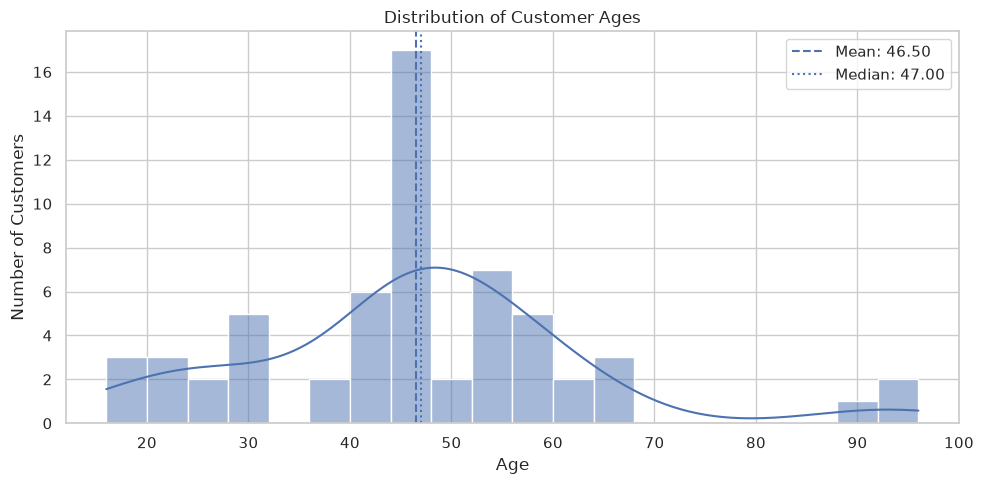

In [12]:
# Visualizar la distribución de edades (Code)

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Edad",
    bins=20,
    kde=True
)

plt.axvline(
    mean_all,
    linestyle="--",
    label=f"Mean: {mean_all:.2f}"
)

plt.axvline(
    median_all,
    linestyle=":",
    label=f"Median: {median_all:.2f}"
)

plt.title("Distribution of Customer Ages")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.legend()
plt.tight_layout()
plt.show()

<CodeBlock language="markdown">## 9. Final Data Quality Validation
After preprocessing, we need to verify that the dataset meets the intended quality requirements.
We will check:
- Remaining missing values.
- Remaining exact duplicate rows.
- Final dimensions.
- Data types.
Validation is important because a cleaning pipeline should demonstrate that the intended transformations were applied successfully.</CodeBlock>

In [13]:
# Comprobaciones finales (Code)

print("===== FINAL VALIDATION =====")

print("Final shape:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())
print("Remaining exact duplicate rows:", df.duplicated().sum())

print("\nMissing values by column:")
display(df.isnull().sum().to_frame(name="Missing Values"))

print("\nFinal data types:")
display(df.dtypes.to_frame(name="Data Type"))

===== FINAL VALIDATION =====
Final shape: (60, 6)
Remaining missing values: 0
Remaining exact duplicate rows: 0

Missing values by column:


,Missing Values
ClienteID,0
Nombre,0
Edad,0
Plan,0
Sucursal,0
DiasAsistidosMes,0



Final data types:


,Data Type
ClienteID,int64
Nombre,str
Edad,float64
Plan,category
Sucursal,str
DiasAsistidosMes,int64


In [14]:
# Exportar el dataset limpio (Code)
output_path = DATA_DIR / "clientes_gimnasio_limpio.csv"

df.to_csv(output_path, index=False)

print("Cleaned dataset saved successfully.")
print("Output file:", output_path)
print("Final dimensions:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())


Cleaned dataset saved successfully.
Output file: /home/chris/Talendig-G-Projects/gym-data-cleaning/data/clientes_gimnasio_limpio.csv
Final dimensions: (60, 6)
Remaining missing values: 0


<CodeBlock language="markdown">## 10. Conclusions and Lessons Learned
This project demonstrates a structured approach to data cleaning and exploratory data analysis.
The workflow includes:
- Inspecting the original dataset before modifying it.
- Quantifying missing values.
- Using different strategies for numerical and categorical variables.
- Considering the context behind missing email addresses.
- Detecting exact duplicate records.
- Representing membership plans as categorical data.
- Comparing mean and median age to understand the influence of extreme observations.
- Validating and exporting the cleaned dataset.
Limitations
- Replacing missing ages with the median does not recover the true age of each customer.
- Replacing missing branches with the mode introduces an assumption that may not reflect the customer's actual branch.
- Removing the Email column means email information is not available in the cleaned analytical dataset.
- Removing exact duplicate rows does not guarantee that every duplicate customer has been identified.
- Excluding ages above 85 was used only for comparison, not as a permanent cleaning rule.
Academic Context
This project was originally developed as part of my Talendig AI/ML training, during Month 4, Week 2. It has been reorganized and documented as part of my personal portfolio to demonstrate my understanding of data cleaning and exploratory data analysis.
Next Steps
Possible improvements include investigating missingness patterns, validating business rules, comparing distributions before and after cleaning, and documenting the impact of each preprocessing decision.</CodeBlock>